# Newcomer retention: event-based vs. organic newcomers

Matched-pair observational study (MCEQ 12576, PUC-Campinas). See `PROTOCOL.md` for the pre-registered analysis plan.

**Unit of analysis:** pair (event-based newcomer, matched organic newcomer from the same project).
**Dependent variable:** activity duration in months (first to last contribution in the project).
**D** = duration(event) − duration(organic).

**Analysis sets** (`PROTOCOL.md`, Amendment 1): the *primary* analysis leaves out the 65 self-matched pairs, where both members are the same GitHub account (n = 1936); the *sensitivity* analysis repeats it on all 2001 pairs.

Sections 1–5 load, validate and describe the data. Sections 6–9 are the confirmatory analysis on the primary set, section 10 the sensitivity analysis and section 11 the exploratory analysis. Every number is saved to `results/results.json`.

Prerequisite: run `uv run python src/prepare_data.py` to generate `data/processed/pairs.csv`.

## 1. Setup

In [1]:
# --- IMPORTS ---
from matplotlib.patches import Patch
from pathlib import Path
from scipy import stats

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy


# --- GLOBALS ---
# repository root, found from either the root or notebooks/
REPO_ROOT = next(
    path
    for path in [Path.cwd(), *Path.cwd().parents]
    if (path / 'PROTOCOL.md').exists()
)
PAIRS_FILE = REPO_ROOT / 'data' / 'processed' / 'pairs.csv'
FIGURES_DIR = REPO_ROOT / 'figures'
RESULTS_FILE = REPO_ROOT / 'results' / 'results.json'

# figure metadata per format: no creation date, so pdfs are reproducible
SAVE_METADATA = {'png': {}, 'pdf': {'CreationDate': None}}

# analysis parameters fixed by PROTOCOL.md
ALPHA = 0.05
N_RESAMPLES = 10_000
SEED = 2026

# scipy's default for the wilcoxon test: pairs with D = 0 are dropped
ZERO_METHOD = 'wilcox'

# sizes the dataset must have, as reported by the replication package
EXPECTED_PAIRS = 2001
EXPECTED_REPOS = 330
EXPECTED_EVENT_COUNTS = {
    'gsoc': 739,
    '24pr': 576,
    'hacktoberfest': 516,
    'lfx': 170,
}

pd.set_option('display.precision', 2)

## 2. Load data

In [2]:
pairs = pd.read_csv(PAIRS_FILE)

# primary set leaves out self-matched pairs; sensitivity set keeps them all
analysis_sets = {
    'primary': pairs[~pairs['self_matched']],
    'sensitivity': pairs,
}

print(pairs.dtypes)
pairs.head()

pair_id               str
repo                  str
event_type            str
mentorship           bool
duration_event      int64
duration_organic    int64
D                   int64
self_matched         bool
dtype: object


,pair_id,repo,event_type,mentorship,duration_event,duration_organic,D,self_matched
0,0rphee__hacktoberfest__haskell__haskell-langua...,haskell/haskell-language-server,hacktoberfest,False,36,1,35,False
1,0shine0__gsoc__movingblocks__terasology,movingblocks/terasology,gsoc,True,6,3,3,False
2,0xflotus__24pr__24pullrequests__24pullrequests,24pullrequests/24pullrequests,24pr,False,1,4,-3,False
3,0xflotus__24pr__apache__nifi,apache/nifi,24pr,False,1,101,-100,False
4,1000miles__24pr__sozialhelden__wheelmap,sozialhelden/wheelmap,24pr,False,32,1,31,False


## 3. Validations

The same checks enforced by `src/prepare_data.py`, run again on the processed file.

In [3]:
durations = pairs[['duration_event', 'duration_organic']]
counts = pairs['event_type'].value_counts().to_dict()
repos = pairs['repo'].nunique()
mentored = pairs['event_type'].isin(['gsoc', 'lfx'])
difference = pairs['duration_event'] - pairs['duration_organic']

# each check, mapped to whether it passed
checks = {
    f'{EXPECTED_PAIRS} pairs (found {len(pairs)})': (
        len(pairs) == EXPECTED_PAIRS
    ),
    'no duplicated pair ids': not pairs['pair_id'].duplicated().any(),
    'no missing durations': not durations.isna().any(axis=None),
    'durations >= 1 month': (durations >= 1).all(axis=None),
    f'{EXPECTED_REPOS} repos (found {repos})': repos == EXPECTED_REPOS,
    f'pairs per event: {counts}': counts == EXPECTED_EVENT_COUNTS,
    'mentorship flag matches event type': (
        pairs['mentorship'] == mentored
    ).all(),
    'D = duration_event - duration_organic': (pairs['D'] == difference).all(),
    'self_matched is a boolean flag': pairs['self_matched'].dtype == bool,
}

# show every check, then fail listing the ones that did not pass
status = {True: 'ok', False: 'FAIL'}
for check, passed in checks.items():
    print(f'[{status[bool(passed)]}] {check}')

failed = [check for check, passed in checks.items() if not passed]
assert not failed, f'Failed checks: {failed}'

[ok] 2001 pairs (found 2001)
[ok] no duplicated pair ids
[ok] no missing durations
[ok] durations >= 1 month
[ok] 330 repos (found 330)
[ok] pairs per event: {'gsoc': 739, '24pr': 576, 'hacktoberfest': 516, 'lfx': 170}
[ok] mentorship flag matches event type
[ok] D = duration_event - duration_organic
[ok] self_matched is a boolean flag


## 4. Counts

In [4]:
print(
    f'Pairs: {len(pairs)}  |  Contributors: {2 * len(pairs)}  |  '
    f'Repositories: {pairs["repo"].nunique()}'
)

# pairs per event type, mentored events first
counts = (
    pairs.groupby(['mentorship', 'event_type'])
    .agg(pairs=('pair_id', 'size'), self_matched=('self_matched', 'sum'))
    .reset_index()
    .sort_values(['mentorship', 'pairs'], ascending=[False, False])
)
counts['primary'] = counts['pairs'] - counts['self_matched']
counts['primary_%'] = 100 * counts['primary'] / counts['primary'].sum()
counts

Pairs: 2001  |  Contributors: 4002  |  Repositories: 330


,mentorship,event_type,pairs,self_matched,primary,primary_%
2,True,gsoc,739,13,726,37.50
3,True,lfx,170,12,158,8.16
0,False,24pr,576,9,567,29.29
1,False,hacktoberfest,516,31,485,25.05


In [5]:
pairs_per_repo = pairs.groupby('repo').size()
pairs_per_repo.describe().to_frame('pairs per repo').T

,count,mean,std,min,25%,50%,75%,max
pairs per repo,330.0,6.06,5.83,1.0,2.0,4.0,8.0,45.0


## 5. Overall descriptive statistics of activity duration (months), by group

For each analysis set. Descriptive only; no inferential comparison is made here.

In [6]:
def describe_durations(pairs: pd.DataFrame) -> pd.DataFrame:
    """
    Summarize the activity duration of each group.

    :param pairs: The pairs to summarize.

    :return: n, mean, median, sd, min and max per group.
    """
    # one column per group, one row per pair
    durations = pairs[['duration_event', 'duration_organic']].rename(
        columns={'duration_event': 'event', 'duration_organic': 'organic'}
    )

    return durations.agg(['count', 'mean', 'median', 'std', 'min', 'max']).T


# one block of rows per analysis set
descriptive = pd.concat(
    {name: describe_durations(data) for name, data in analysis_sets.items()}
)
descriptive.columns = ['n', 'mean', 'median', 'sd', 'min', 'max']
descriptive.astype({'n': int, 'min': int, 'max': int})

n   mean  median     sd  min  max
primary     event    1936  21.11     8.0  30.06    1  188
            organic  1936  21.17     6.0  31.93    1  272
sensitivity event    2001  21.07     8.0  29.80    1  188
            organic  2001  21.34     7.0  31.91    1  272

---
# Confirmatory analysis

Sections 6–9 use the primary set (n = 1936), following `PROTOCOL.md` sections 2–4.

## 6. Normality of D (Shapiro–Wilk, α = 0.05)

In [7]:
# test the protocol prescribes, by whether normality of D is rejected
TEST_BY_NORMALITY_REJECTED = {
    False: 'paired t-test',
    True: 'Wilcoxon signed-rank',
}

# how each kind of value is printed
FORMATS = {float: '{:.6g}'}


def show(result: dict) -> None:
    """
    Print each entry of a result, one per line.

    :param result: The result to print.

    :return: None.
    """
    for key, value in result.items():
        text = FORMATS.get(type(value), '{}').format(value)
        print(f'  {key:<20} {text}')


def test_normality(d: np.ndarray) -> dict:
    """
    Run the Shapiro-Wilk test on D and pick the main test from its result.

    :param d: The paired differences.

    :return: W, p, whether normality is rejected and the test to use.
    """
    result = stats.shapiro(d)
    rejected = bool(result.pvalue < ALPHA)

    return {
        'W': float(result.statistic),
        'p': float(result.pvalue),
        'normality_rejected': rejected,
        'main_test': TEST_BY_NORMALITY_REJECTED[rejected],
    }


primary_d = analysis_sets['primary']['D'].to_numpy()
normality = test_normality(primary_d)

print(f'Shapiro-Wilk on D, primary set (n = {len(primary_d)}):')
show(normality)

Shapiro-Wilk on D, primary set (n = 1936):
  W                    0.89705
  p                    3.54789e-34
  normality_rejected   True
  main_test            Wilcoxon signed-rank


## 7. Main test (paired t-test, or Wilcoxon signed-rank if normality is rejected)

In [8]:
# decision on H0, by whether p < alpha
DECISIONS = {True: 'reject H0', False: 'do not reject H0'}


def paired_t_test(d: np.ndarray) -> dict:
    """
    Run the paired t-test, as a one-sample t-test of D against 0.

    :param d: The paired differences.

    :return: t, its degrees of freedom and p.
    """
    result = stats.ttest_1samp(d, 0.0)

    return {
        'statistic_name': 't',
        'statistic': float(result.statistic),
        'df': len(d) - 1,
        'p': float(result.pvalue),
    }


def wilcoxon_test(d: np.ndarray) -> dict:
    """
    Run the two-sided Wilcoxon signed-rank test on D.

    :param d: The paired differences.

    :return: T (the smaller signed-rank sum), the pairs it used and p.
    """
    result = stats.wilcoxon(d, zero_method=ZERO_METHOD)

    return {
        'statistic_name': 'T',
        'statistic': float(result.statistic),
        'n_nonzero': int(np.count_nonzero(d)),
        'zero_method': ZERO_METHOD,
        'p': float(result.pvalue),
    }


# each main test, by name
MAIN_TESTS = {
    'paired t-test': paired_t_test,
    'Wilcoxon signed-rank': wilcoxon_test,
}


def run_main_test(d: np.ndarray, test_name: str) -> dict:
    """
    Run the main test the protocol picked and decide on H0.

    :param d: The paired differences.
    :param test_name: The test to run, a key of MAIN_TESTS.

    :return: The test's results and the decision at ALPHA.
    """
    result = MAIN_TESTS[test_name](d)

    return {
        'name': test_name,
        **result,
        'decision': DECISIONS[result['p'] < ALPHA],
    }


def describe_d(d: np.ndarray) -> dict:
    """
    Summarize D and count the pairs on each side of zero.

    :param d: The paired differences.

    :return: n, mean, median, sd and the pairs with D > 0, D < 0 and D = 0.
    """
    return {
        'n': len(d),
        'mean': float(np.mean(d)),
        'median': float(np.median(d)),
        'sd': float(np.std(d, ddof=1)),
        'D > 0': int(np.sum(d > 0)),
        'D < 0': int(np.sum(d < 0)),
        'D = 0': int(np.sum(d == 0)),
    }


main_test = run_main_test(primary_d, normality['main_test'])
d_summary = describe_d(primary_d)

print(f'Main test, primary set (alpha = {ALPHA}):')
show(main_test)
pd.DataFrame([d_summary], index=['primary'])

Main test, primary set (alpha = 0.05):
  name                 Wilcoxon signed-rank
  statistic_name       T
  statistic            709646
  n_nonzero            1708
  zero_method          wilcox
  p                    0.324152
  decision             do not reject H0


,n,mean,median,sd,D > 0,D < 0,D = 0
primary,1936,-0.06,0.0,37.37,884,824,228


## 8. Effect size + bootstrap 95% CI (10,000 resamples, `default_rng(2026)`)

**Formulas** (`PROTOCOL.md`, section 4):

- Paired t-test → **Cohen's d_z** = mean(D) / sd(D), with the sample sd (n − 1).
- Wilcoxon signed-rank → **matched-pairs rank-biserial correlation** r = (R⁺ − R⁻) / (R⁺ + R⁻), where R⁺ and R⁻ are the sums of the ranks of |D| (average ranks for ties) over the pairs with D > 0 and D < 0. It ranges from −1 to 1; r > 0 means event members tend to have the longer duration.

**D = 0 in the Wilcoxon test:** SciPy's default `zero_method='wilcox'` is used and passed explicitly. It drops the pairs with D = 0 before ranking, so the test statistic, the n it reports and r are all computed on the same nonzero pairs. The number of pairs dropped is the `D = 0` count in section 7. SciPy's default `method='auto'` is also kept; with this many pairs (and with ties) it uses the normal approximation for the p-value.

**CI:** percentile bootstrap. Each resample draws n pairs with replacement (D is one value per pair) and recomputes the effect size; the CI is the 2.5th and 97.5th percentiles of the 10,000 estimates. Every analysis starts its own `numpy.random.default_rng(2026)`, so each result can be reproduced on its own.

In [9]:
def cohens_dz(d: np.ndarray) -> float:
    """
    Compute Cohen's d_z for paired data.

    :param d: The paired differences.

    :return: d_z.
    """
    # d_z = mean(D) / sd(D), sample sd with n - 1
    return float(np.mean(d) / np.std(d, ddof=1))


def rank_biserial(d: np.ndarray) -> float:
    """
    Compute the matched-pairs rank-biserial correlation.

    :param d: The paired differences.

    :return: r, between -1 and 1.
    """
    # drop D = 0, as zero_method='wilcox' does in the test
    nonzero = d[d != 0]
    ranks = stats.rankdata(np.abs(nonzero))

    # r = (R+ - R-) / (R+ + R-), ranks of |D| summed by the sign of D
    positive, negative = ranks[nonzero > 0].sum(), ranks[nonzero < 0].sum()
    return float((positive - negative) / (positive + negative))


# effect size of each main test: its name and how it is computed
EFFECT_SIZES = {
    'paired t-test': ('d_z', cohens_dz),
    'Wilcoxon signed-rank': ('rank-biserial r', rank_biserial),
}


def bootstrap_ci(d: np.ndarray, effect) -> tuple[float, float]:
    """
    Compute a 95% percentile bootstrap CI by resampling pairs.

    :param d: The paired differences.
    :param effect: The function that computes the effect size from D.

    :return: The lower and upper bounds of the CI.
    """
    # a new generator per call, so each analysis is reproducible on its own
    rng = np.random.default_rng(SEED)
    estimates = [
        effect(rng.choice(d, size=len(d))) for _ in range(N_RESAMPLES)
    ]

    low, high = np.percentile(estimates, [2.5, 97.5])
    return float(low), float(high)


def estimate_effect(d: np.ndarray, test_name: str) -> dict:
    """
    Compute the effect size of the main test and its bootstrap CI.

    :param d: The paired differences.
    :param test_name: The main test, a key of EFFECT_SIZES.

    :return: The effect size, its CI and how the CI was computed.
    """
    name, effect = EFFECT_SIZES[test_name]
    low, high = bootstrap_ci(d, effect)

    return {
        'name': name,
        'value': effect(d),
        'ci_95_low': low,
        'ci_95_high': high,
        'ci_method': 'percentile bootstrap, resampling pairs',
        'n_resamples': N_RESAMPLES,
        'seed': SEED,
    }


def run_protocol(d: np.ndarray) -> dict:
    """
    Run sections 6-8 of the analysis on one set of paired differences.

    :param d: The paired differences.

    :return: Normality, the summary of D, the main test and the effect size.
    """
    normality = test_normality(d)
    test_name = normality['main_test']

    return {
        'normality': normality,
        'd_summary': describe_d(d),
        'main_test': run_main_test(d, test_name),
        'effect_size': estimate_effect(d, test_name),
    }


effect_size = estimate_effect(primary_d, normality['main_test'])

print('Effect size, primary set:')
show(effect_size)

# every number of the analysis, saved at the end of the notebook
results = {
    'parameters': {
        'alpha': ALPHA,
        'n_resamples': N_RESAMPLES,
        'seed': SEED,
        'zero_method': ZERO_METHOD,
        'wilcoxon_method': 'auto (normal approximation at these sample sizes)',
        'ci_level': 0.95,
        'scipy_version': scipy.__version__,
        'numpy_version': np.__version__,
    },
    'primary': {
        'normality': normality,
        'd_summary': d_summary,
        'main_test': main_test,
        'effect_size': effect_size,
    },
}

Effect size, primary set:
  name                 rank-biserial r
  value                0.0275398
  ci_95_low            -0.0281441
  ci_95_high           0.0825634
  ci_method            percentile bootstrap, resampling pairs
  n_resamples          10000
  seed                 2026


## 9. Figure

Distribution of D in the primary set, sized for one column of the ACM template (8.5 cm wide).

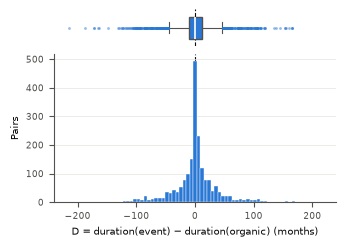

In [10]:
# figure size: one acm column, in inches
FIGURE_SIZE = (8.5 / 2.54, 6.0 / 2.54)

# colors: data in blue, text and reference marks in near-black and gray
COLORS = {
    'data': '#2a78d6',
    'text': '#0b0b0b',
    'muted': '#52514e',
    'grid': '#e4e3df',
}

# bins of 6 months, centered on 0
BIN_WIDTH = 6

plt.rcParams.update(
    {
        'font.size': 7,
        'axes.labelsize': 7,
        'xtick.labelsize': 6.5,
        'ytick.labelsize': 6.5,
        'axes.edgecolor': COLORS['muted'],
        'axes.labelcolor': COLORS['text'],
        'xtick.color': COLORS['muted'],
        'ytick.color': COLORS['muted'],
        'pdf.fonttype': 42,
    }
)

edge = BIN_WIDTH * np.ceil(np.abs(primary_d).max() / BIN_WIDTH) + BIN_WIDTH / 2
bins = np.arange(-edge, edge + BIN_WIDTH, BIN_WIDTH)

# boxplot on top shows quartiles and tails; histogram below shows the shape
figure, (box_axis, hist_axis) = plt.subplots(
    2,
    1,
    sharex=True,
    figsize=FIGURE_SIZE,
    gridspec_kw={'height_ratios': [1, 4]},
    layout='constrained',
)

box_axis.boxplot(
    primary_d,
    orientation='horizontal',
    widths=0.6,
    patch_artist=True,
    boxprops={'facecolor': COLORS['data'], 'edgecolor': COLORS['muted']},
    medianprops={'color': 'white', 'linewidth': 1.2},
    whiskerprops={'color': COLORS['muted'], 'linewidth': 0.8},
    capprops={'color': COLORS['muted'], 'linewidth': 0.8},
    flierprops={
        'marker': 'o',
        'markersize': 2,
        'markerfacecolor': COLORS['data'],
        'markeredgewidth': 0,
        'alpha': 0.5,
    },
)
box_axis.set_yticks([])
box_axis.spines[['top', 'right', 'left', 'bottom']].set_visible(False)
box_axis.tick_params(axis='x', length=0)

hist_axis.hist(
    primary_d,
    bins=bins,
    color=COLORS['data'],
    edgecolor='white',
    linewidth=0.3,
)
hist_axis.set_xlabel('D = duration(event) − duration(organic) (months)')
hist_axis.set_ylabel('Pairs')
hist_axis.spines[['top', 'right']].set_visible(False)
hist_axis.grid(axis='y', color=COLORS['grid'], linewidth=0.5)
hist_axis.set_axisbelow(True)

# reference line at D = 0, behind the data, across both panels
for axis in (box_axis, hist_axis):
    axis.axvline(
        0, color=COLORS['text'], linewidth=0.8, linestyle='--', zorder=0
    )

# save for the paper, in print and vector formats
FIGURES_DIR.mkdir(exist_ok=True)
for extension in ('png', 'pdf'):
    figure.savefig(
        FIGURES_DIR / f'd_distribution.{extension}',
        dpi=300,
        facecolor='white',
        metadata=SAVE_METADATA[extension],
    )

plt.show()

## 10. Sensitivity analysis: all 2001 pairs

Same procedure as sections 6–8, including the 65 self-matched pairs (`PROTOCOL.md`, Amendment 1).

In [11]:
def show_protocol(result: dict) -> None:
    """
    Print every part of a run_protocol result.

    :param result: The result of run_protocol.

    :return: None.
    """
    for part, values in result.items():
        print(f'{part}:')
        show(values)


sensitivity_d = analysis_sets['sensitivity']['D'].to_numpy()
results['sensitivity'] = run_protocol(sensitivity_d)

print(f'Sensitivity set (n = {len(sensitivity_d)}):')
show_protocol(results['sensitivity'])

Sensitivity set (n = 2001):
normality:
  W                    0.890737
  p                    1.78174e-35
  normality_rejected   True
  main_test            Wilcoxon signed-rank
d_summary:
  n                    2001
  mean                 -0.268366
  median               0
  sd                   36.9855
  D > 0                886
  D < 0                840
  D = 0                275
main_test:
  name                 Wilcoxon signed-rank
  statistic_name       T
  statistic            730576
  n_nonzero            1726
  zero_method          wilcox
  p                    0.480008
  decision             do not reject H0
effect_size:
  name                 rank-biserial r
  value                0.0196249
  ci_95_low            -0.0347454
  ci_95_high           0.0731546
  ci_method            percentile bootstrap, resampling pairs
  n_resamples          10000
  seed                 2026


---
# Exploratory analysis

## 11. Exploratory analysis: mentorship (gsoc, lfx) vs. no mentorship (hacktoberfest, 24pr)

*Exploratory — not part of the confirmatory hypothesis test.* Same procedure as sections 6–8, run separately for each group of the primary set.

In [12]:
# results key of each group, by its mentorship flag
EXPLORATORY_GROUPS = {
    True: 'exploratory_mentorship',
    False: 'exploratory_no_mentorship',
}

primary = analysis_sets['primary']
for mentorship, key in EXPLORATORY_GROUPS.items():
    group_d = primary.loc[primary['mentorship'] == mentorship, 'D'].to_numpy()
    results[key] = run_protocol(group_d)

    print(f'{key} (n = {len(group_d)}), EXPLORATORY:')
    show_protocol(results[key])
    print()

exploratory_mentorship (n = 884), EXPLORATORY:
normality:
  W                    0.827527
  p                    8.49621e-30
  normality_rejected   True
  main_test            Wilcoxon signed-rank
d_summary:
  n                    884
  mean                 -0.0644796
  median               0
  sd                   25.9794
  D > 0                434
  D < 0                341
  D = 0                109
main_test:
  name                 Wilcoxon signed-rank
  statistic_name       T
  statistic            133014
  n_nonzero            775
  zero_method          wilcox
  p                    0.00540879
  decision             reject H0
effect_size:
  name                 rank-biserial r
  value                0.115304
  ci_95_low            0.032895
  ci_95_high           0.197018
  ci_method            percentile bootstrap, resampling pairs
  n_resamples          10000
  seed                 2026



exploratory_no_mentorship (n = 1052), EXPLORATORY:
normality:
  W                    0.944966
  p                    2.40386e-19
  normality_rejected   True
  main_test            Wilcoxon signed-rank
d_summary:
  n                    1052
  mean                 -0.0589354
  median               0
  sd                   44.7729
  D > 0                450
  D < 0                483
  D = 0                119
main_test:
  name                 Wilcoxon signed-rank
  statistic_name       T
  statistic            214670
  n_nonzero            933
  zero_method          wilcox
  p                    0.698767
  decision             do not reject H0
effect_size:
  name                 rank-biserial r
  value                -0.0146244
  ci_95_low            -0.0870969
  ci_95_high           0.0599342
  ci_method            percentile bootstrap, resampling pairs
  n_resamples          10000
  seed                 2026



### Figure 2 (exploratory): pairs by sign of D, per mentorship group

Primary set. Share of pairs in which the event member stayed longer (D > 0), both stayed the same (D = 0) or the organic member stayed longer (D < 0). Sized for one ACM column (8.5 × 4 cm).

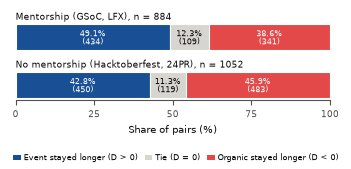

In [13]:
# figure size: one acm column, in inches
SPLIT_FIGURE_SIZE = (8.5 / 2.54, 4.0 / 2.54)

# bars from top to bottom: results key and label of each group
SPLIT_GROUPS = {
    'exploratory_mentorship': 'Mentorship (GSoC, LFX)',
    'exploratory_no_mentorship': 'No mentorship (Hacktoberfest, 24PR)',
}

# segments in order: legend label, d_summary key, fill and text colors
SEGMENTS = [
    ('Event stayed longer (D > 0)', 'D > 0', '#184f95', 'white'),
    ('Tie (D = 0)', 'D = 0', '#d6d5d0', COLORS['text']),
    ('Organic stayed longer (D < 0)', 'D < 0', '#e34948', 'white'),
]

# a segment narrower than this share (%) shows its percentage only
MIN_SHARE_FOR_COUNT = 8
LABEL_FORMATS = {
    True: '{share:.1f}%\n({count})',
    False: '{share:.1f}%',
}

BAR_HEIGHT = 0.55

figure, axis = plt.subplots(figsize=SPLIT_FIGURE_SIZE, layout='constrained')

# one bar per group, each segment labelled with its share and count
for position, (key, group) in enumerate(SPLIT_GROUPS.items()):
    summary = results[key]['d_summary']
    left = 0.0

    for _, column, fill, ink in SEGMENTS:
        count = summary[column]
        share = 100 * count / summary['n']
        axis.barh(
            -position,
            share,
            left=left,
            height=BAR_HEIGHT,
            color=fill,
            edgecolor='white',
            linewidth=0.8,
        )
        text = LABEL_FORMATS[share >= MIN_SHARE_FOR_COUNT]
        axis.text(
            left + share / 2,
            -position,
            text.format(share=share, count=count),
            ha='center',
            va='center',
            color=ink,
            fontsize=5.5,
            linespacing=1.0,
        )
        left += share

    # group name and size above its bar
    axis.text(
        0,
        -position + BAR_HEIGHT / 2 + 0.04,
        f'{group}, n = {summary["n"]}',
        ha='left',
        va='bottom',
        fontsize=6.5,
        color=COLORS['text'],
    )

axis.set_xlim(0, 100)
axis.set_xticks([0, 25, 50, 75, 100])
axis.set_xlabel('Share of pairs (%)')
axis.set_yticks([])
axis.set_ylim(-1 - BAR_HEIGHT / 2 - 0.05, BAR_HEIGHT / 2 + 0.3)
axis.spines[['top', 'right', 'left']].set_visible(False)

# legend below the plot, one entry per segment
figure.legend(
    handles=[
        Patch(facecolor=fill, edgecolor='none', label=label)
        for label, _, fill, _ in SEGMENTS
    ],
    loc='outside lower center',
    ncol=3,
    frameon=False,
    fontsize=5.5,
    handlelength=1.0,
    handletextpad=0.4,
    columnspacing=0.9,
)

# save for the paper, in print and vector formats
for extension in ('png', 'pdf'):
    figure.savefig(
        FIGURES_DIR / f'mentorship_split.{extension}',
        dpi=300,
        facecolor='white',
        metadata=SAVE_METADATA[extension],
    )

plt.show()

## Save results

Every number above, one key per analysis, in `results/results.json`.

In [14]:
RESULTS_FILE.parent.mkdir(exist_ok=True)
RESULTS_FILE.write_text(json.dumps(results, indent=2) + '\n', encoding='utf-8')

print(f'Wrote {RESULTS_FILE.relative_to(REPO_ROOT)}: {list(results)}')

Wrote results/results.json: ['parameters', 'primary', 'sensitivity', 'exploratory_mentorship', 'exploratory_no_mentorship']
